# **In this project we are exploring tech   diversity all over the world**

# Analyzing Tech Diversity: A Look at Google's Ethnicity Data (2014-2023)

This notebook explores the provided dataset on ethnicity diversity at Google from 2014 to 2023. The goal is to understand the trends and patterns in the representation of different ethnic groups within the company over this period. We will perform data cleaning, feature engineering, feature selection, and dimensionality reduction techniques to prepare the data for analysis and visualization. Finally, we will build a predictive model to explore potential relationships between different ethnic groups' representation over time.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder,MinMaxScaler

Loading dataset "Google_Ethnicity.cs"

In [ ]:
# Make sure to run the cell above that imports pandas as pd first.
df = pd.read_csv("google_ethnicity.csv")
print(df)

NameError: name 'pd' is not defined

Classifying datatypes as categorical, discrete, continuous

In [ ]:
categorical_cols = []
numerical_cols = []
continuous=[]
discrete=[]

for col in df.columns:
  dtype=df[col].dtype
  if dtype == 'object' or dtype=="categorical":
    categorical_cols.append(col)
  elif pd.api.types.is_numeric_dtype(df[col]):
    unique_values=df[col].nunique()
    if pd.api.types.is_integer_dtype(df[col]) and unique_values < 20:
      discrete.append(col)
    else:
      continuous.append(col)

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)
print("Continuous columns:", continuous)
print("Discrete columns:", discrete)

Categorical columns: ['Asian+', 'Black+', 'Latinx+', 'Native American+*', 'White+']
Numerical columns: []
Continuous columns: []
Discrete columns: ['Characteristic']


Checking for null values

In [ ]:
# Re-load the dataframe to ensure it's not overwritten
df = pd.read_csv("google_ethnicity.csv")

# Check for null values (this will return a boolean dataframe, but not overwrite df)
null_check_df = df.isnull()
print(null_check_df)

   Characteristic  Asian+  Black+  Latinx+  Native American+*  White+
0           False   False   False    False              False   False
1           False   False   False    False              False   False
2           False   False   False    False              False   False
3           False   False   False    False              False   False
4           False   False   False    False              False   False
5           False   False   False    False              False   False
6           False   False   False    False              False   False
7           False   False   False    False              False   False
8           False   False   False    False              False   False
9           False   False   False    False              False   False


Applying  Normalization by using `MinMax Scaler`

In [ ]:
# Remove '%' and convert to numeric for relevant columns
cols_to_clean = ['Asian+', 'Black+', 'Latinx+', 'Native American+*', 'White+']
for col in cols_to_clean:
  df[col] = df[col].str.replace('%', '', regex=False).astype(float)

m=MinMaxScaler()
minmax=m.fit_transform(df[cols_to_clean])
print(minmax,"MinMax Scaling")

[[0.         0.         0.         1.         1.        ]
 [0.09022556 0.03125    0.14285714 1.         0.91256831]
 [0.18045113 0.125      0.25       0.71428571 0.80874317]
 [0.36090226 0.125      0.28571429 0.71428571 0.67213115]
 [0.4962406  0.1875     0.28571429 0.         0.56830601]
 [0.62406015 0.28125    0.42857143 0.71428571 0.44808743]
 [0.78195489 0.40625    0.5        0.71428571 0.30054645]
 [0.81203008 0.625      0.67857143 0.71428571 0.2295082 ]
 [0.87969925 0.90625    0.85714286 0.71428571 0.1147541 ]
 [1.         1.         1.         0.71428571 0.        ]] MinMax Scaling


Converting categorical column into numeric using label encoding method

In [ ]:
#labelencoding the categorical values
le=LabelEncoder()
for col in categorical_cols:
  df[col]=le.fit_transform(df[col])
print(df)

   Characteristic  Asian+  Black+  Latinx+  Native American+*  White+
0            2014       0       0        0                  2       9
1            2015       1       1        1                  2       8
2            2016       2       2        2                  1       7
3            2017       3       2        3                  1       6
4            2018       4       3        3                  0       5
5            2019       5       4        4                  1       4
6            2020       6       5        5                  1       3
7            2021       7       6        6                  1       2
8            2022       8       7        7                  1       1
9            2023       9       8        8                  1       0


Convertion using One hot encoder

In [ ]:
# OneHotEncoding of the discrete values in the given dataset
ohe=OneHotEncoder()
onehot=ohe.fit_transform(df[discrete])
print(onehot)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10 stored elements and shape (10, 10)>
  Coords	Values
  (0, 0)	1.0
  (1, 1)	1.0
  (2, 2)	1.0
  (3, 3)	1.0
  (4, 4)	1.0
  (5, 5)	1.0
  (6, 6)	1.0
  (7, 7)	1.0
  (8, 8)	1.0
  (9, 9)	1.0


In [ ]:


m=MinMaxScaler()
minmax=m.fit_transform(df[cols_to_clean])
print(minmax,"MinMax Scaling")

[[0.         0.         0.         1.         1.        ]
 [0.11111111 0.125      0.125      1.         0.88888889]
 [0.22222222 0.25       0.25       0.5        0.77777778]
 [0.33333333 0.25       0.375      0.5        0.66666667]
 [0.44444444 0.375      0.375      0.         0.55555556]
 [0.55555556 0.5        0.5        0.5        0.44444444]
 [0.66666667 0.625      0.625      0.5        0.33333333]
 [0.77777778 0.75       0.75       0.5        0.22222222]
 [0.88888889 0.875      0.875      0.5        0.11111111]
 [1.         1.         1.         0.5        0.        ]] MinMax Scaling


Insertion of new feature years_since _start from existing feature Characteristics

In [ ]:
# Assuming 'Characteristic' is the year
# Create a new feature: Years since the first year
first_year = df['Characteristic'].min()
df['Years_Since_Start'] = df['Characteristic'] - first_year

# Display the updated dataframe with the new feature
print(df[['Characteristic', 'Years_Since_Start']].head())

   Characteristic  Years_Since_Start
0            2014                  0
1            2015                  1
2            2016                  2
3            2017                  3
4            2018                  4


In [ ]:
from sklearn.preprocessing import PolynomialFeatures


poly_features_complex = PolynomialFeatures(degree=3, include_bias=False)


years_since_start_reshaped = df[['Years_Since_Start']]


complex_features = poly_features_complex.fit_transform(years_since_start_reshaped)


complex_features_df = pd.DataFrame(complex_features, columns=[f'Years_Since_Start_poly_{i+1}' for i in range(complex_features.shape[1])])


print("Original 'Years_Since_Start' column:")
print(df[['Years_Since_Start']].head())
print("\nGenerated complex polynomial features:")
print(complex_features_df.head())

Original 'Years_Since_Start' column:
   Years_Since_Start
0                  0
1                  1
2                  2
3                  3
4                  4

Generated complex polynomial features:
   Years_Since_Start_poly_1  Years_Since_Start_poly_2  \
0                       0.0                       0.0   
1                       1.0                       1.0   
2                       2.0                       4.0   
3                       3.0                       9.0   
4                       4.0                      16.0   

   Years_Since_Start_poly_3  
0                       0.0  
1                       1.0  
2                       8.0  
3                      27.0  
4                      64.0  


Applying Feature extraction using Random Forest Regressor method

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Instantiate a RandomForestRegressor model
rf_model = RandomForestRegressor(random_state=42)

# Define features (X) and target (y)
# Assuming you want to predict 'Asian+' based on other ethnicity percentages and the new feature 'Years_Since_Start'
features = ['Black+', 'Latinx+', 'Native American+*', 'White+', 'Years_Since_Start']
target = 'Asian+'

X = df[features]
y = df[target]


# Fit the model to the data
rf_model.fit(X, y)

# Get feature importances
rf_feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)

# Sort feature importances in descending order
rf_feature_importances = rf_feature_importances.sort_values(ascending=False)

# Display sorted feature importances
print("Random Forest Feature Importances:")
display(rf_feature_importances)

Random Forest Feature Importances:


,0
Black+,0.266991
White+,0.251872
Years_Since_Start,0.248860
Latinx+,0.217120
Native American+*,0.015156


Proccessing Feature Selection

In [ ]:
correlation_matrix = df.corr()
target_correlation = correlation_matrix['Asian+'].sort_values(ascending=False)
print("Correlation with 'Asian+':")
print(target_correlation)

# Consider dropping features with low absolute correlation to 'Asian+' (e.g., < 0.05)
low_correlation_threshold = 0.05
low_correlation_features = target_correlation[abs(target_correlation) < low_correlation_threshold].index.tolist()

print(f"\nFeatures with absolute correlation less than {low_correlation_threshold} with 'Asian+':")
print(low_correlation_features)


features_for_multicollinearity = correlation_matrix.drop('Asian+', axis=1).index # Corrected 'target' to 'Asian+'
multicollinearity_matrix = correlation_matrix.loc[features_for_multicollinearity, features_for_multicollinearity]

# Find highly correlated feature pairs (absolute correlation > 0.8)
high_correlation_threshold = 0.8
highly_correlated_pairs = {}
for i in range(len(multicollinearity_matrix.columns)):
    for j in range(i):
        if abs(multicollinearity_matrix.iloc[i, j]) > high_correlation_threshold:
            col1 = multicollinearity_matrix.columns[i]
            col2 = multicollinearity_matrix.columns[j]
            highly_correlated_pairs[(col1, col2)] = multicollinearity_matrix.iloc[i, j]

print(f"\nHighly correlated feature pairs (absolute correlation > {high_correlation_threshold}):")
if highly_correlated_pairs:
    for pair, corr in highly_correlated_pairs.items():
        print(f"{pair}: {corr:.4f}")
else:
    print("No highly correlated feature pairs found above the threshold.")

Correlation with 'Asian+':
Characteristic       1.000000
Asian+               1.000000
Years_Since_Start    1.000000
Latinx+              0.994612
Black+               0.993978
Native American+*   -0.484881
White+              -1.000000
Name: Asian+, dtype: float64

Features with absolute correlation less than 0.05 with 'Asian+':
[]

Highly correlated feature pairs (absolute correlation > 0.8):
('Asian+', 'Characteristic'): 1.0000
('Black+', 'Characteristic'): 0.9940
('Black+', 'Asian+'): 0.9940
('Latinx+', 'Characteristic'): 0.9946
('Latinx+', 'Asian+'): 0.9946
('Latinx+', 'Black+'): 0.9930
('White+', 'Characteristic'): -1.0000
('White+', 'Asian+'): -1.0000
('White+', 'Black+'): -0.9940
('White+', 'Latinx+'): -0.9946
('Years_Since_Start', 'Characteristic'): 1.0000
('Years_Since_Start', 'Asian+'): 1.0000
('Years_Since_Start', 'Black+'): 0.9940
('Years_Since_Start', 'Latinx+'): 0.9946
('Years_Since_Start', 'White+'): -1.0000


Applying Principle Component Analysis on selected feature

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler # Import StandardScaler
import pandas as pd

cols_to_scale = ['Asian+', 'Black+', 'Latinx+', 'Native American+*', 'White+']
df_to_scale = df[cols_to_scale]


scaler = StandardScaler()


df_scaled = scaler.fit_transform(df_to_scale)


df_scaled = pd.DataFrame(df_scaled, columns=cols_to_scale)


pca = PCA()
pca.fit(df_scaled)
df_pca = pca.transform(df_scaled)

pca_columns = [f'PC{i+1}' for i in range(df_pca.shape[1])]
df_pca = pd.DataFrame(df_pca, columns=pca_columns)


print("Explained variance ratio of the principal components:")
display(pca.explained_variance_ratio_)

print("\nCumulative explained variance ratio:")
display(pca.explained_variance_ratio_.cumsum())

print("\nPCA transformed data (first 5 rows):")
display(df_pca.head())

Explained variance ratio of the principal components:


array([0.84922681, 0.14843088, 0.00137164, 0.00097067, 0.        ])


Cumulative explained variance ratio:


array([0.84922681, 0.99765769, 0.99902933, 1.        , 1.        ])


PCA transformed data (first 5 rows):


,PC1,PC2,PC3,PC4,PC5
0,-3.448368,0.758976,-0.042474,-0.032825,1.208803e-16
1,-2.727969,0.966339,-0.027683,0.008005,2.658427e-16
2,-1.500919,-0.608871,-0.023974,0.166699,1.237251e-16
3,-0.970227,-0.472415,0.239129,-0.026046,1.251475e-16
4,0.062458,-2.111223,-0.070378,-0.023161,-7.112075e-19


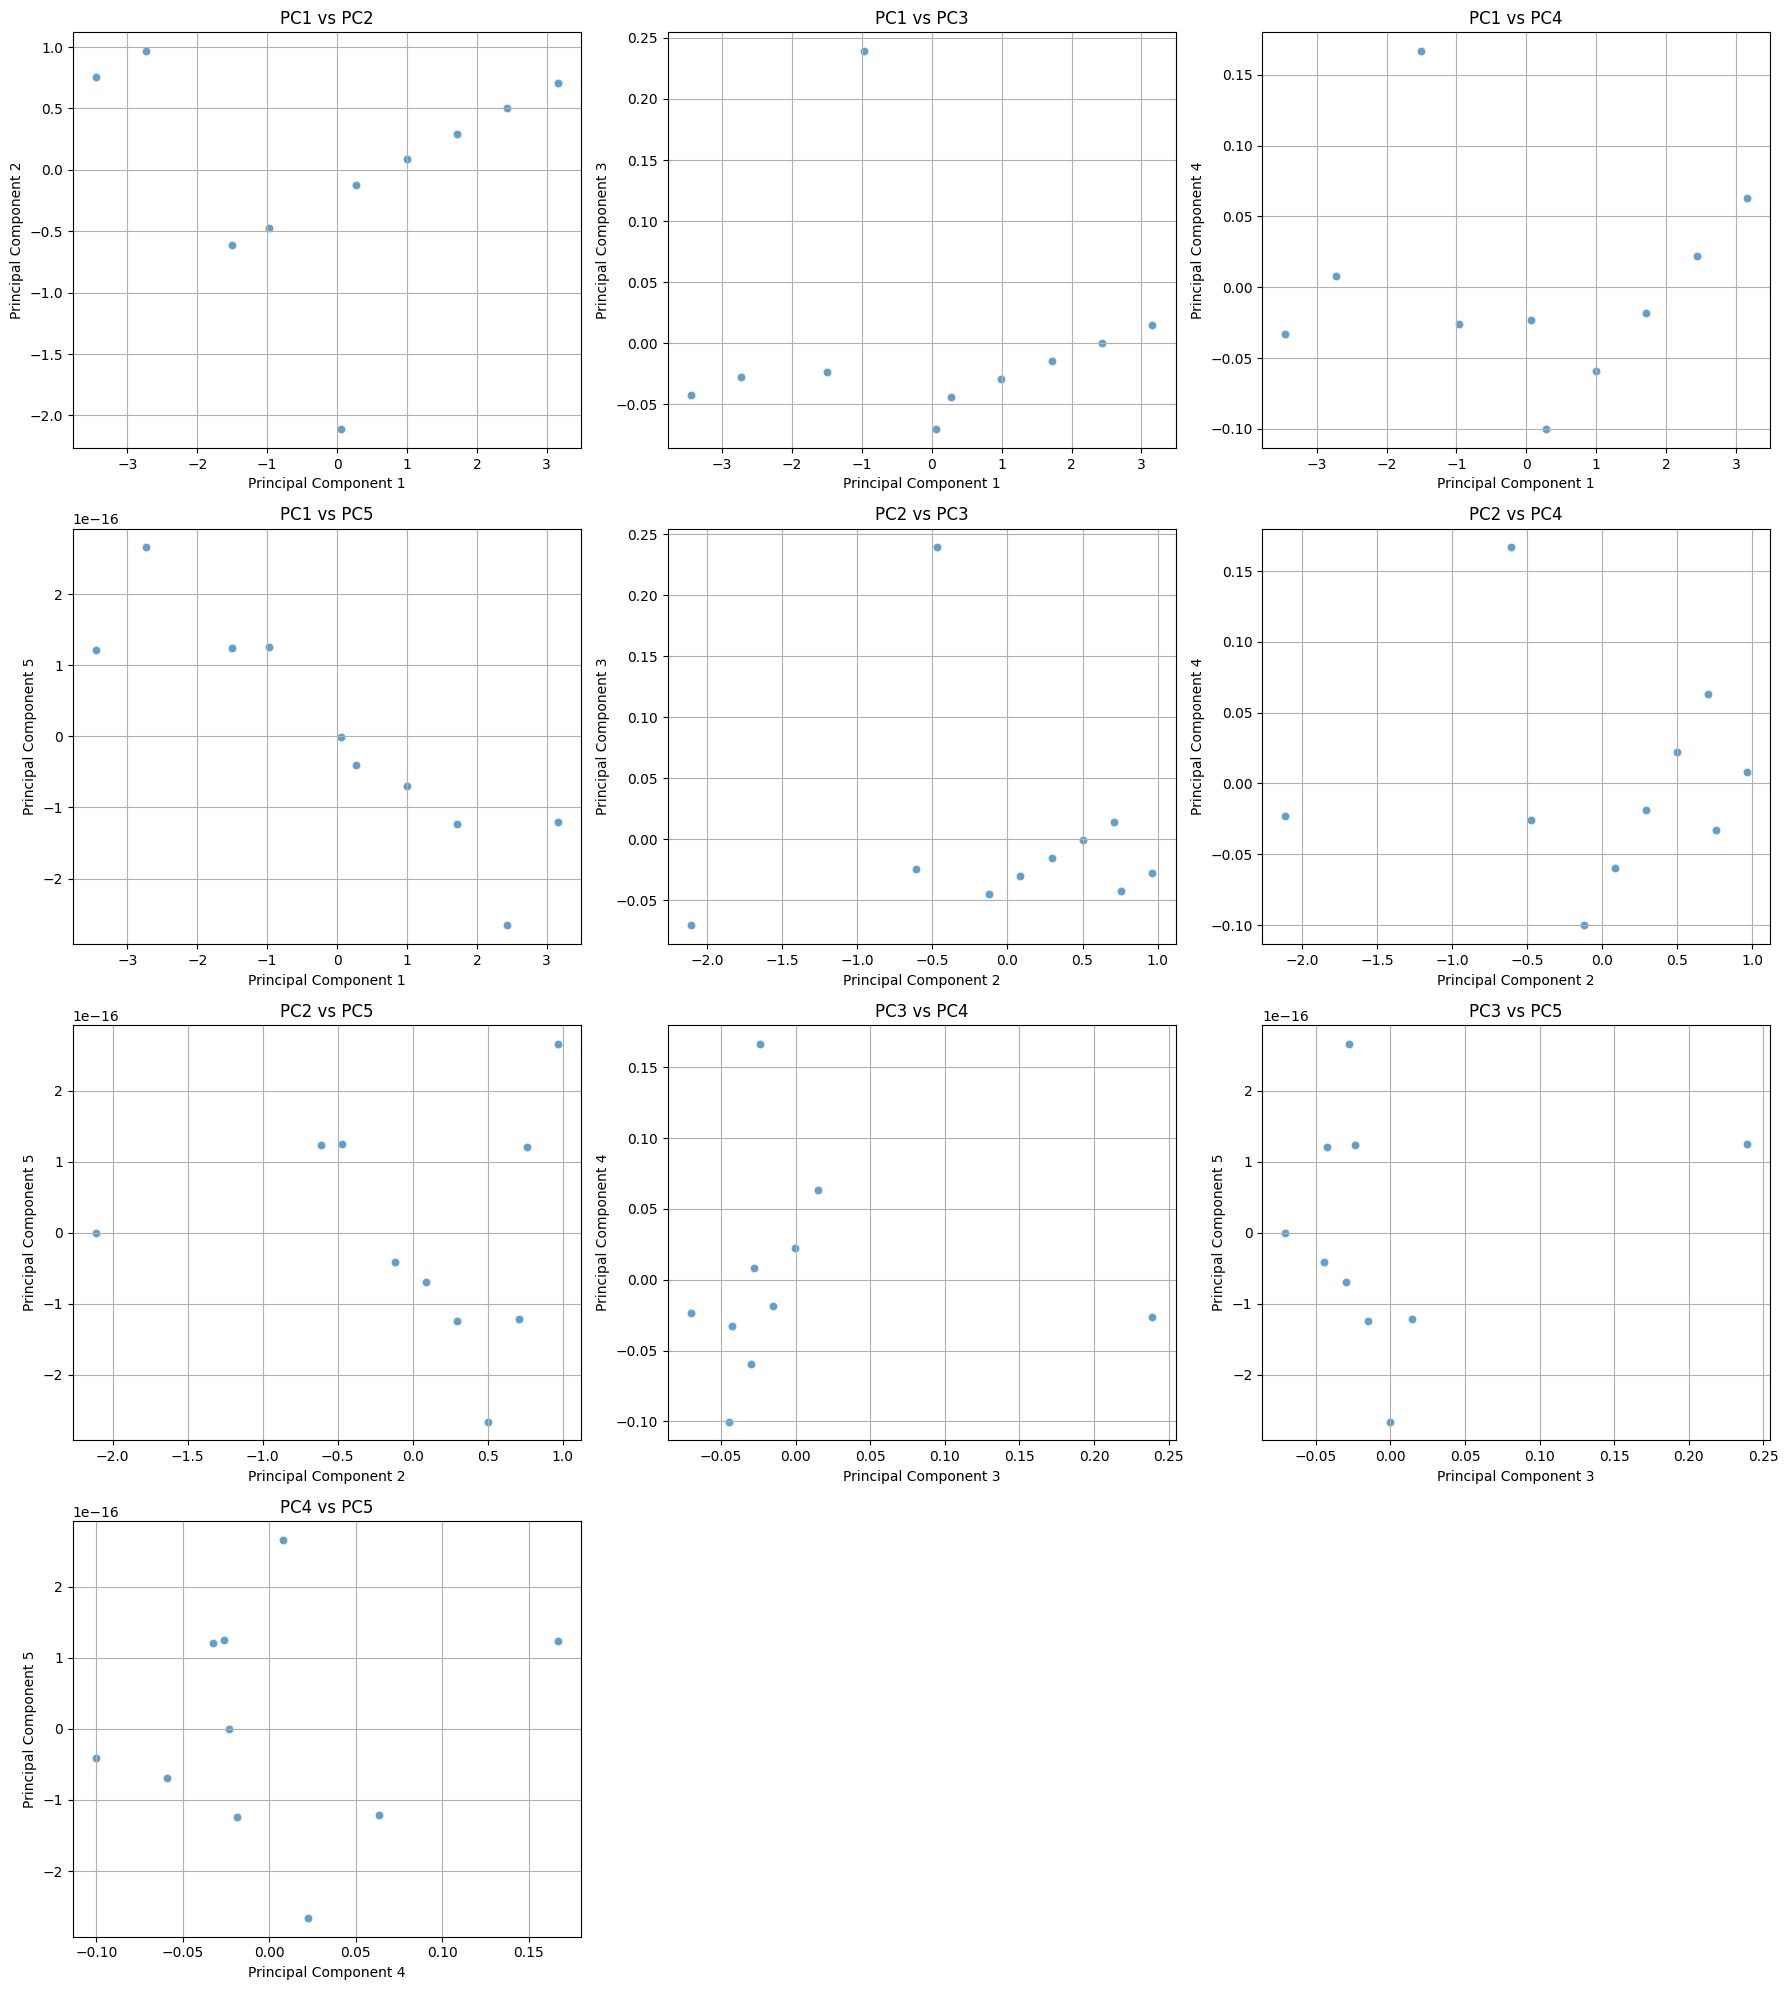

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_components = df_pca.shape[1]

if n_components > 1:
    # Calculate the number of rows and columns for subplots
    n_plots = (n_components * (n_components - 1)) // 2
    n_cols = min(n_plots, 3) # Limit to a maximum of 3 columns
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 5))
    axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

    plot_index = 0
    for i in range(n_components):
        for j in range(i + 1, n_components):
            sns.scatterplot(x=df_pca[f'PC{i+1}'], y=df_pca[f'PC{j+1}'], alpha=0.7, ax=axes[plot_index])
            axes[plot_index].set_xlabel(f'Principal Component {i+1}')
            axes[plot_index].set_ylabel(f'Principal Component {j+1}')
            axes[plot_index].set_title(f'PC{i+1} vs PC{j+1}')
            axes[plot_index].grid(True)
            plot_index += 1

    # Hide any unused subplots
    for k in range(plot_index, len(axes)):
        fig.delaxes(axes[k])

    plt.tight_layout()
    plt.show()
else:
    print("Only one principal component found, cannot create scatter plots between components.")

Plotting Histogram for the dataset

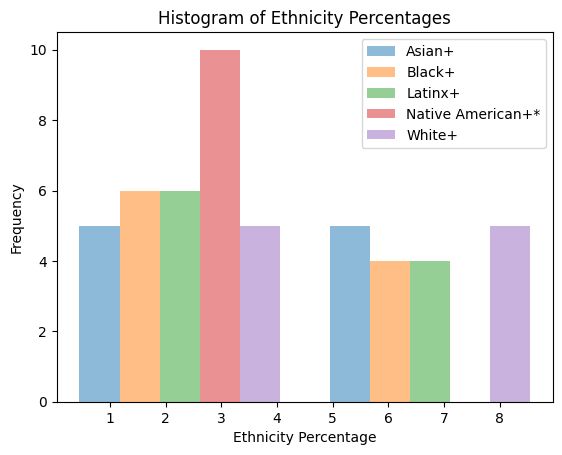

In [ ]:
plt.hist(df[[ 'Asian+', 'Black+', 'Latinx+', 'Native American+*', 'White+']], bins=2, alpha=0.5, label=['Asian+', 'Black+', 'Latinx+', 'Native American+*', 'White+'])
plt.legend()
plt.title("Histogram of Ethnicity Percentages")
plt.xlabel("Ethnicity Percentage")
plt.ylabel("Frequency")
plt.show()

Showing the correlation of attributes

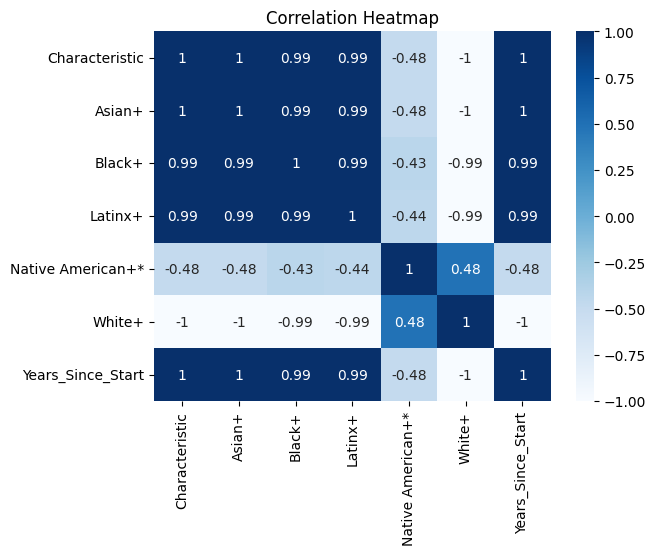

In [ ]:
c=df.corr()
sns.heatmap(c,annot=True,cmap='Blues')
plt.title('Correlation Heatmap')
plt.show()

Final display of the preprocessed dataset with feature engineering has done.

In [ ]:
# Displaying dataset after preprocessing,visualisation,feature extraction and selection the attributes
display(df)

,Characteristic,Asian+,Black+,Latinx+,Native American+*,White+,Years_Since_Start
0,2014,0,0,0,2,9,0
1,2015,1,1,1,2,8,1
2,2016,2,2,2,1,7,2
3,2017,3,2,3,1,6,3
4,2018,4,3,3,0,5,4
5,2019,5,4,4,1,4,5
6,2020,6,5,5,1,3,6
7,2021,7,6,6,1,2,7
8,2022,8,7,7,1,1,8
9,2023,9,8,8,1,0,9


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


features = ['Black+', 'Latinx+', 'Native American+*', 'White+', 'Years_Since_Start']
target = 'Asian+'

X = df[features]
y = df[target]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = LinearRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)


mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")


results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print("\nActual vs Predicted (Test Set):")
display(results)

Mean Squared Error: 0.00
R-squared: 1.00

Actual vs Predicted (Test Set):


,Actual,Predicted
8,8,8.0
1,1,1.0


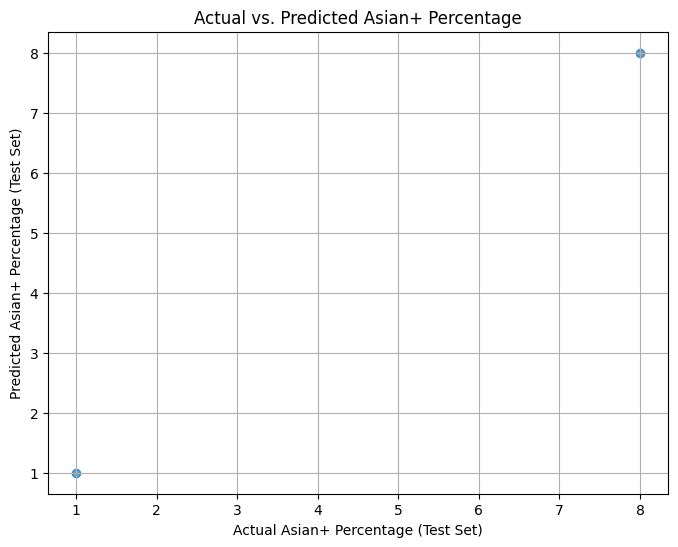

In [ ]:
# Visualize the actual vs. predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.xlabel("Actual Asian+ Percentage (Test Set)")
plt.ylabel("Predicted Asian+ Percentage (Test Set)")
plt.title("Actual vs. Predicted Asian+ Percentage")
plt.grid(True)
plt.show()

# In this plot, points that fall close to a diagonal line from the bottom-left to the top-right indicate good model performance, where the predicted values are close to the actual values. Given the R-squared of 1.00, you would expect all points to lie exactly on this diagonal line.



## Conclusion

This notebook focused on exploring and analyzing the Google ethnicity diversity dataset, applying various data preprocessing, feature engineering, and machine learning techniques. The key steps performed include:

- **Data Loading and Inspection**: Loaded the dataset and identified column data types and potential issues.
- **Data Cleaning**: Removed percentage signs and converted ethnicity columns to numeric format.
- **Feature Scaling**: Applied MinMax scaling to normalize the numeric ethnicity data.
- **Feature Encoding**: Used Label Encoding for categorical columns and One-Hot Encoding for discrete features to prepare them for analysis.
- **Feature Engineering**: Created a `Years_Since_Start` feature from the 'Characteristic' column and generated complex polynomial features.
- **Feature Selection**: Analyzed feature importances using Random Forest and examined feature correlations to understand relationships and identify multicollinearity.
- **Dimensionality Reduction**: Applied Principal Component Analysis (PCA) to reduce the dimensionality of the scaled ethnicity data and visualize the main components.
- **Model Training and Evaluation**: Trained a Linear Regression model to predict the 'Asian+' percentage based on selected features and evaluated its performance using Mean Squared Error and R-squared.
- **Prediction**: Demonstrated how to use the trained model to make predictions on new (sample) data.



